# TP 1 : Apprentissage supervisé - Exercice 2 (Titanic)
## Étape 1 : Chargement et exploration


In [ ]:
import pandas as pd

data = pd.read_csv('titanic.csv')
print(data.head())
print(data.info())
print(data.isnull().sum())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
<c

## Étape 2 : Nettoyage et traitement

In [ ]:
# Sélection des colonnes pertinentes
data = data[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]

# Remplacement des valeurs manquantes
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])

# Vérification
print(data.isnull().sum())

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


## Étape 3 et 4 : Encodage et Séparation des données

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
# Transformation du texte en nombres 
data['Sex'] = le.fit_transform(data['Sex'])
data['Embarked'] = le.fit_transform(data['Embarked'])

# Séparation des données
X = data.drop('Survived', axis=1)
y = data['Survived']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Encodage et séparation terminés !")
print("Aperçu des données encodées :\n", X_train[['Sex', 'Embarked']].head())

Encodage et séparation terminés !
Aperçu des données encodées :
      Sex  Embarked
331    1         2
733    1         2
382    1         2
704    1         2
813    0         2


## Étapes 5 et 6 : Entraînement et Évaluation des modèles

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Initialisation des modèles 
log_model = LogisticRegression(max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Entraînement
log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# Évaluation des modèles
from sklearn.metrics import accuracy_score, classification_report

# Prédictions
y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

# Affichage des résultats
print('--- Précision globale (Accuracy) ---')
print('Régression Logistique :', accuracy_score(y_test, y_pred_log))
print('Random Forest         :', accuracy_score(y_test, y_pred_rf))

print('\n--- Rapport détaillé pour Random Forest ---')
print(classification_report(y_test, y_pred_rf))

--- Précision globale (Accuracy) ---
Régression Logistique : 0.8100558659217877
Random Forest         : 0.8212290502793296

--- Rapport détaillé pour Random Forest ---
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       105
           1       0.81      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



## Étape 7 : Matrice de confusion

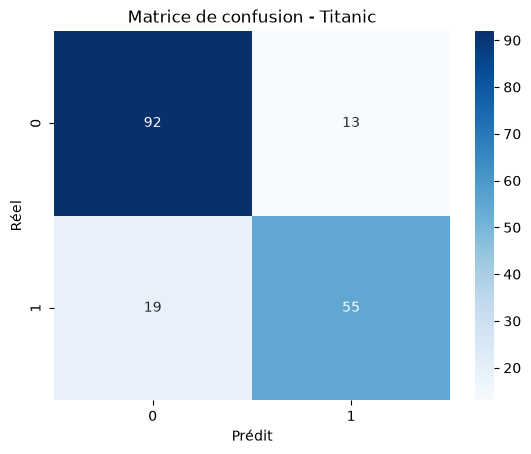

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion - Titanic')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.show()

### Interprétation de la Matrice de Confusion

La matrice de confusion nous permet de voir exactement où le modèle Random Forest a réussi et où il s'est trompé sur nos données de test :

* **92 Vrais Négatifs (en haut à gauche) :** Le modèle a prédit correctement la mort de 92 passagers.
* **55 Vrais Positifs (en bas à droite) :** Le modèle a prédit correctement la survie de 55 passagers.
* **13 Faux Positifs (en haut à droite) :** Le modèle a prédit que 13 passagers allaient survivre, mais ils sont malheureusement décédés.
* **19 Faux Négatifs (en bas à gauche) :** Le modèle a prédit que 19 passagers allaient mourir, alors qu'ils ont survécu.

**Conclusion :** Le modèle est globalement très performant (147 prédictions correctes contre 32 erreurs). Il a cependant une légère tendance à être pessimiste (plus de faux négatifs que de faux positifs), ce qui est typique sur le dataset du Titanic où la majorité des passagers ont péri.